# Demonstration of the BFORE Python Module

First, import modules. In addition to the bfore module, we use meshplot to allow us to (interactively) render a mesh; matplotlib.pyplot for plotting images; and numpy for various transformation routines.

In [1]:
import meshplot as mp
import bfore as bf
import matplotlib.pyplot as plt
import numpy as np

## Exploring Meshes

Let's make a Star object (a subclass of Mesh object) and initialize it by reading from an HDF5-format file created using the **build_star** code:

In [2]:
star = bf.Star('star.h5')

The geometry and connectivity data in Mesh objects (and subclasses) is accessible through a pair of functions that return numpy.ndarray objects:

In [3]:
# vert_points() returns a 2D numpy.ndarray containing the Cartesian coordinates of each
# vertex in the mesh

vp = star.vert_points()

i = 6

print(f"The vertex with index {i} has coordinates {vp[i,:]}")

# face_verts() returns an 2D numpy.ndarray giving the indices of the three vertices
# associated with each triangular face

fv = star.face_verts()

j = 3

print(f"The face with index {j} is associated with vertices with indices {fv[j,:]}")

The vertex with index 6 has coordinates [ 0.74721469  0.54288325 -0.46180407]
The face with index 3 is associated with vertices with indices [301 275 121]


We can use the connectivity data, together with the meshplot module, to create an interactive rendering of a Mesh object:

In [4]:
# Create an interactive rendering (use drag-click to rotate, mouse wheel to zoom)

mp.plot(star.vert_points(), star.face_verts())

Renderer(camera=PerspectiveCamera(children=(DirectionalLight(color='white', intensity=0.6, position=(0.0, 0.0,…

In addition to geometry and connectivity data, Mesh objects contain scalar and vector attributes assiated with each vertex:

In [5]:
# Show how many scalar and vector attributes the Mesh object has

print(f"There are {star.n_scalar} scalar attributes")
print(f"There are {star.n_vector} vector attributes")

# Access a scalar attribute

a = 1

vs = star.vert_scalars(a)

print(f"The scalar attribute with index {a} of the vertex with index {i} has the value {vs[i]}")

# Access a vector attribute

b = 2

vv = star.vert_vectors(b)

print(f"The scalar attribute with index {b} of the vertex with index {j} has the value {vv[j]}")


There are 2 scalar attributes
There are 3 vector attributes
The scalar attribute with index 1 of the vertex with index 6 has the value 0.8771503503780023
The scalar attribute with index 2 of the vertex with index 3 has the value [ 0.62325586 -0.45282189 -0.41940101]


Having to access scalar/vector attributes by index rather than name is a bit clunky, and this will likely change in the future. But for now, the mappings between index and name are as follows:

* Scalar attribute 0 is Teff (in units of the polar temperature)
* Scalar attribute 1 is g (in units of the polar gravity)

* Vector attribute 0 is the surface normal vector
* Vector attribute 1 is the velocity vector (in units of the Keplerian velocity)
* Vector attribute 2 is the local gravity vector (with length g)

These mappings can be seen in the file src/star/star_m.fypp file (note that Python and Fortran indices differ by 1).

Scalar attributes (and, single components of vector attributes) can be added to the interactive rendering by adding a third argument to meshplot.plot():

In [6]:
# Show the effective temperature in the interactive rendering

mp.plot(star.vert_points(), star.face_verts(), star.vert_scalars(0))


Renderer(camera=PerspectiveCamera(children=(DirectionalLight(color='white', intensity=0.6, position=(0.0, 0.0,…

## Exploring Rbuffs

Now let's make a Rbuff (render buffer) object and initialize it by reading from an HDF5-format file created using the **render_mesh** code:

In [7]:
rbuff = bf.Rbuff('rbuff.h5')

An Rbuff object is essentially an image of the mesh, but rather than containing the usual red, blue, green color data for each pixel, it stores scalar and vector attribute values. These data are accessible through a pair of functions that return numpy.MaskedArray objects (MaskedArray objects are used, rather than ndarray, because parts of a Rbuff that do not cover a star are "empty space" and therefore have no valid value associated with them):

In [8]:
# pixel_scalars(a) returns a 2D numpy.MaskedArray containing the 
# pixel data for the scalar attribute with index a

a = 1

ps = rbuff.pixel_scalars(a)

print(f"The pixel data for the scalar attribute with index {a} is a {type(ps)} object with shape {ps.shape}")

# pixel_vectors(b) returns a 3D numpy.MaskedArray containing the
# pixel data for the vector attribute with index b

b = 2

pv = rbuff.pixel_vectors(b)

print(f"The pixel data for the vector attribute with index {b} is a {type(pv)} object with shape {pv.shape}")


The pixel data for the scalar attribute with index 1 is a <class 'numpy.ma.core.MaskedArray'> object with shape (4096, 4096)
The pixel data for the vector attribute with index 2 is a <class 'numpy.ma.core.MaskedArray'> object with shape (4096, 4096, 3)


We can use matplotlib's imshow() function to display the data for a specific attribute as an image (note the use of the origin argument, to ensure the orientation is correct):

Text(0.5, 1.0, 'Radial velocity')

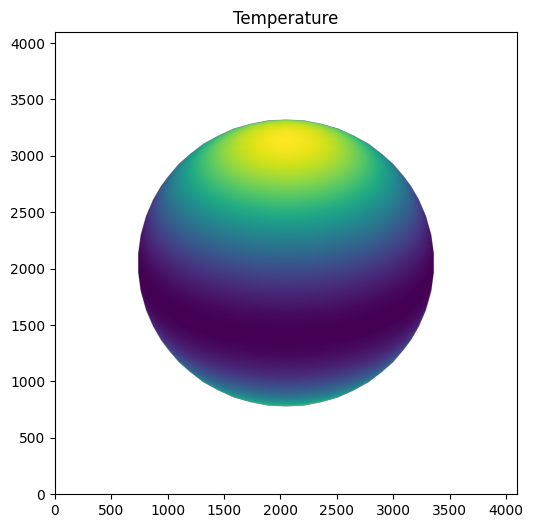

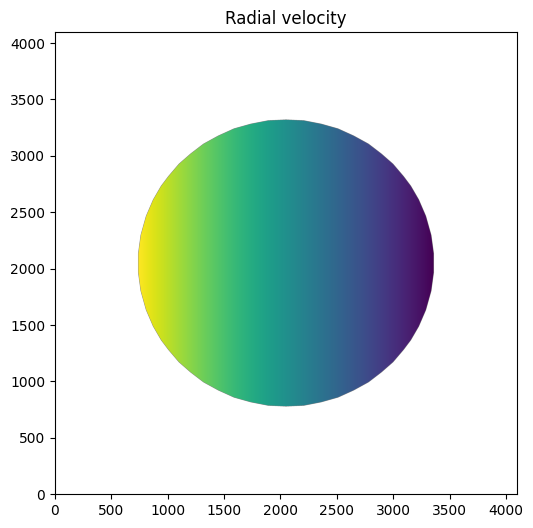

In [9]:
# Plot the temperature attribute of the Rbuff object

plt.figure(figsize=[6,6])

plt.imshow(rbuff.pixel_scalars(0), origin='lower')
plt.title('Temperature')

# Plot the z-component of the velocity attribute of the Rbuff object
# (this corresponds to the observer-frame radial velocity)

plt.figure(figsize=[6,6])

plt.imshow(rbuff.pixel_vectors(1)[:,:,2], origin='lower')
plt.title('Radial velocity')


## Exploring Streams

Finally, let's make a Stream object and initialize it by reading from an HDF5-format file created using either the **stream_mesh** or the **render_and_stream_mesh** code:

In [10]:
stream = bf.Stream('stream.h5')

A Stream object is composed of a sequence of fragments ("frags" for short). Each fragment can be regarded as an agglomeration of a group of Rbuff pixels, with associated scalar and vector attribute values together with an area (measured in units of the polar radius squared). These data are accessible through three functions that return numpy.ndarray objects:

In [11]:
# frag_scalars(a) returns a 1D numpy.ndarray containing the fragment
# data for the scalar attribute with index a

a = 1

fs = stream.frag_scalars(a)

print(f"The fragment data for the scalar attribute with index {a} is a {type(fs)} object with shape {fs.shape}")

# frag_vectors(b) returns a 2D numpy.ndarray containing the fragment
# data for the vector attribute with index b

b = 2

fv = stream.frag_vectors(b)

print(f"The fragment data for the vector attribute with index {b} is a {type(fv)} object with shape {fv.shape}")

# frag_areas() returns a 1D numpy.ndarray containing the fragment 
# area data

fa = stream.frag_areas()

print(f"The fragment area data is a {type(fa)} object with shape {fa.shape}")



The fragment data for the scalar attribute with index 1 is a <class 'numpy.ndarray'> object with shape (20732,)
The fragment data for the vector attribute with index 2 is a <class 'numpy.ndarray'> object with shape (20732, 3)
The fragment area data is a <class 'numpy.ndarray'> object with shape (20732,)


Stream objects contain all the data necessary to perform spectral/color synthesis (in both unpolarized and polarized light). Here's an example of how one might go about evaluating the bolometric flux, assuming that the emitting surface is a blackbody with a linear limb-darkening law:

In [12]:
# Define stellar parameters (cgs), based on what Google Gemini thinks
# a main-sequence B4 star looks like

import astropy.constants as ac

MASS = 5.10*ac.M_sun.cgs.value
R_POLE = 3.46*ac.R_sun.cgs.value
T_POLE = 16400
G_POLE = ac.G.cgs.value*MASS/R_POLE**2

U_LIMB = 0.6  # linear limb-darkening parameter
DIST = 10*ac.pc.cgs.value

# Extract fragment attribue and area data from the stream

fs_Teff = stream.frag_scalars(0)
fs_g = stream.frag_scalars(1)

fv_norm = stream.frag_vectors(0)
fv_v = stream.frag_vectors(1)
fv_g = stream.frag_vectors(2)

fa = stream.frag_areas()

# Loop over fragments, summing up the flux

flux = 0

for i in range(stream.n):

    # Evaluate fragment quantities (in cgs)

    Teff = fs_Teff[i]*T_POLE
    g = fs_g[i]*G_POLE # Not used for blackbody

    norm = fv_norm[i]
    mu = norm[2] # Only need the normal z-component for unpolarized synthesis

    v = fv_v[i]*np.sqrt(G_POLE*R_POLE)
    v_r = norm[2] # Not used for color synthesis

    a = fa[i]*R_POLE**2

    # Evaluate the observer-directed specific intensity

    I = ac.sigma_sb.cgs.value*Teff**4*(1 - U_LIMB*(1 - mu))/(np.pi*(1 - U_LIMB/3))

    # Accumulate the observed flux at distance DIST
    
    flux += I*a/(DIST**2)

print(f"The bolometric flux is {flux} erg/s/cm^2")

The bolometric flux is 0.00011685178798430576 erg/s/cm^2
